# Assignment 54 — Week 6, Day 4
## Topic: Machine Learning — Support Vector Machines

**Objective:** Complete the exercise on Support Vector Machines (SVM).

**Reference:** https://stackabuse.com/implementing-svm-and-kernel-svm-with-pythons-scikit-learn/

A Support Vector Machine (SVM) is a classifier that finds the **hyperplane** (a line in 2-D) that separates the classes with the **largest margin**. The points closest to the boundary are the **support vectors**; they alone decide where the boundary goes. When the classes cannot be separated by a straight line, a **kernel** lets the SVM draw curved boundaries.

This notebook follows the Stack Abuse tutorial: a linear SVM on banknote data (`bill_authentication.csv`, which must be in the same folder), then kernel SVMs on the iris data set.

**Diagram:** The decision boundary, its margin and the support vectors on example data.

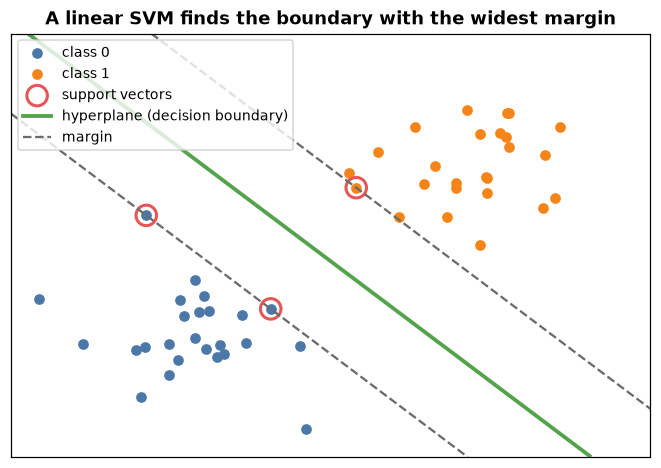

**Load the banknote authentication dataset**

In [1]:
import pandas as pd

bankdata = pd.read_csv("bill_authentication.csv")

print(bankdata.shape)
print(bankdata.head())
print(bankdata["Class"].value_counts())

(1372, 5)
   Variance  Skewness  Curtosis  Entropy  Class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
Class
0    762
1    610
Name: count, dtype: int64


**Explanation:** Each row describes an image of a banknote with 4 features (Variance, Skewness, Curtosis and Entropy). Class is 1 for a forged note and 0 for a genuine one.

**Train a linear SVM**

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

bankdata = pd.read_csv("bill_authentication.csv")

X = bankdata.drop("Class", axis=1)
y = bankdata["Class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

svclassifier = SVC(kernel="linear")
svclassifier.fit(X_train, y_train)

y_pred = svclassifier.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[146   2]
 [  2 125]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       148
           1       0.98      0.98      0.98       127

    accuracy                           0.99       275
   macro avg       0.99      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



**Explanation:** SVC(kernel='linear') finds the straight boundary (hyperplane) that separates the two classes with the widest margin. The classification report shows precision, recall and F1-score for each class.

**Diagram:** Why kernels help: data that is not separable in its original form can become separable after a transformation.

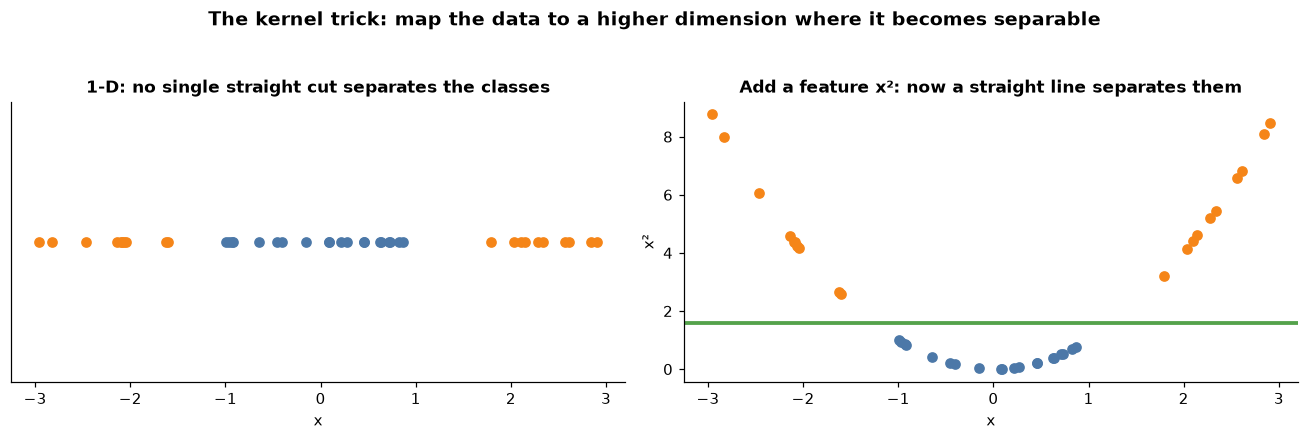

**Load the iris dataset for kernel SVM**

In [3]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
irisdata = iris.frame
irisdata["Class"] = irisdata["target"].map(dict(enumerate(iris.target_names)))
irisdata = irisdata.drop("target", axis=1)

print(irisdata.head())
print(irisdata["Class"].value_counts())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

    Class  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
Class
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Explanation:** The iris dataset has 150 flowers from 3 species, with 4 measurements each. Its classes can't all be split with straight lines, so it is used to test non-linear kernels.

**Compare the polynomial, Gaussian (RBF) and sigmoid kernels**

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.20, random_state=42)

kernels = {
    "Polynomial": SVC(kernel="poly", degree=8),
    "Gaussian (RBF)": SVC(kernel="rbf"),
    "Sigmoid": SVC(kernel="sigmoid"),
}

for name, svclassifier in kernels.items():
    svclassifier.fit(X_train, y_train)
    y_pred = svclassifier.predict(X_test)
    print(f"===== {name} kernel =====")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

===== Polynomial kernel =====
Accuracy: 0.9666666666666667
[[10  0  0]
 [ 0  8  1]
 [ 0  0 11]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.89      0.94         9
   virginica       0.92      1.00      0.96        11

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.97        30
weighted avg       0.97      0.97      0.97        30

===== Gaussian (RBF) kernel =====
Accuracy: 1.0
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

===== Sigmoid kernel =====
Accuracy: 0.3
[[ 0 10  0]
 [ 0

**Explanation:** A kernel maps the data into a higher dimension where the classes can be separated. The polynomial and Gaussian kernels classify the iris data well. The sigmoid kernel does poorly, because it suits data that is split into two classes in a different way.

## Observation

- An SVM chooses the boundary with the widest margin between the classes; only the support vectors affect it.
- The linear SVM classifies the banknotes with about 99% accuracy, because those classes are almost linearly separable.
- Kernels map the data into a higher dimension so curved boundaries become possible.
- On the iris data, the Gaussian (RBF) and polynomial kernels perform very well, while the sigmoid kernel performs poorly.

## Conclusion

SVMs are powerful classifiers for both linearly and non-linearly separable data. Choosing the right kernel for the data is the key decision, so comparing several kernels is good practice.